Customer Dataset:
    Customer_ID  Annual_Spending  Visits_Per_Month
0             1            15000                 2
1             2            18000                 3
2             3            20000                 2
3             4            22000                 4
4             5            25000                 3
5             6            30000                 5
6             7            32000                 6
7             8            35000                 5
8             9            38000                 7
9            10            40000                 6
10           11            45000                 8
11           12            48000                 9
12           13            50000                 8
13           14            52000                10
14           15            55000                 9
15           16            60000                11
16           17            65000                12
17           18            70000                11
18           

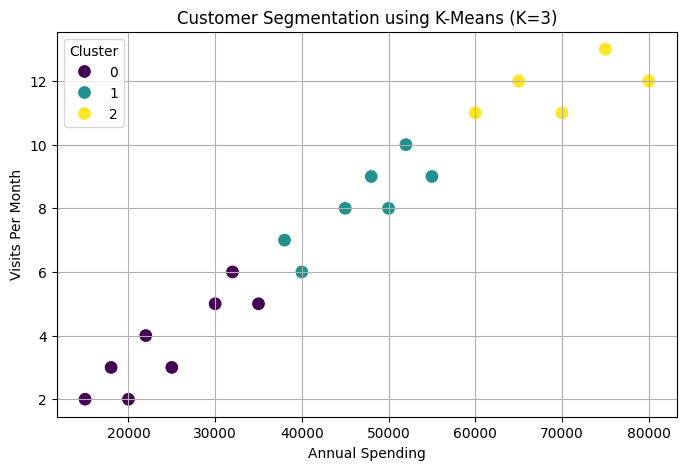

Average Annual Spending for Each Cluster:
Cluster
0    24625.000000
1    46857.142857
2    70000.000000
Name: Annual_Spending, dtype: float64
K-Means Comparison Results:
   K    Inertia  Silhouette Score
0  2  10.245265          0.586687
1  3   4.773774          0.525179
2  4   2.141025          0.561278


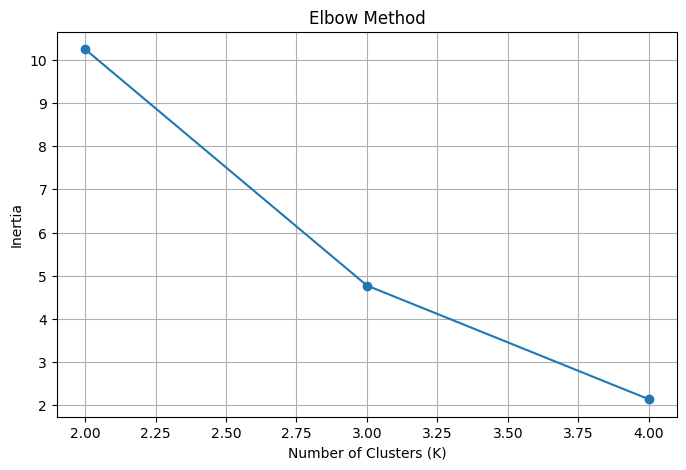

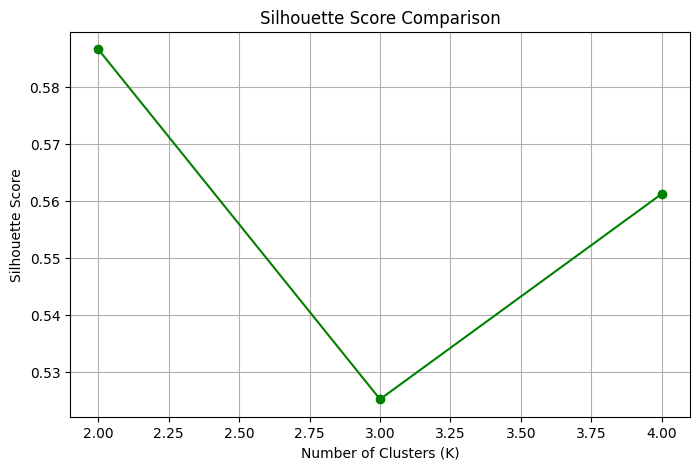

DBSCAN Clustering Results:
    Customer_ID  Annual_Spending  Visits_Per_Month  Cluster  DBSCAN_Cluster
0             1            15000                 2        0               0
1             2            18000                 3        0               0
2             3            20000                 2        0               0
3             4            22000                 4        0               0
4             5            25000                 3        0               0
5             6            30000                 5        0               1
6             7            32000                 6        0               1
7             8            35000                 5        0               1
8             9            38000                 7        1               1
9            10            40000                 6        1               1
10           11            45000                 8        1               1
11           12            48000                 9        1  

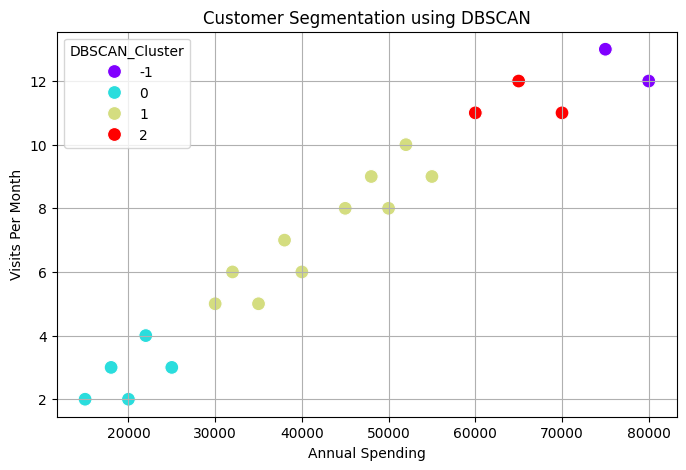

Noise Points:
    Customer_ID  Annual_Spending  Visits_Per_Month  Cluster  DBSCAN_Cluster
18           19            75000                13        2              -1
19           20            80000                12        2              -1


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score

data = {
    'Customer_ID': range(1, 21),
    'Annual_Spending': [
        15000, 18000, 20000, 22000, 25000,
        30000, 32000, 35000, 38000, 40000,
        45000, 48000, 50000, 52000, 55000,
        60000, 65000, 70000, 75000, 80000
    ],
    'Visits_Per_Month': [
        2, 3, 2, 4, 3,
        5, 6, 5, 7, 6,
        8, 9, 8, 10, 9,
        11, 12, 11, 13, 12
    ]
}

df = pd.DataFrame(data)


print("Customer Dataset:")
print(df)


X = df[['Annual_Spending', 'Visits_Per_Month']]


scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_scaled)


print("K-Means Clustering Results:")
print(df)

# Visualise clusters
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='Annual_Spending',
    y='Visits_Per_Month',
    hue='Cluster',
    palette='viridis',
    s=100
)

plt.title('Customer Segmentation using K-Means (K=3)')
plt.xlabel('Annual Spending')
plt.ylabel('Visits Per Month')
plt.legend(title='Cluster')
plt.grid(True)
plt.show()


average_spending = df.groupby('Cluster')['Annual_Spending'].mean()

print("Average Annual Spending for Each Cluster:")
print(average_spending)


k_values = [2, 3, 4]
inertia_values = []
silhouette_values = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)

    inertia_values.append(model.inertia_)
    silhouette_values.append(silhouette_score(X_scaled, labels))


results = pd.DataFrame({
    'K': k_values,
    'Inertia': inertia_values,
    'Silhouette Score': silhouette_values
})

print("K-Means Comparison Results:")
print(results)


plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia_values, marker='o')
plt.title('Elbow Method')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.grid(True)
plt.show()


plt.figure(figsize=(8, 5))
plt.plot(k_values, silhouette_values, marker='o', color='green')
plt.title('Silhouette Score Comparison')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.grid(True)
plt.show()


dbscan = DBSCAN(eps=0.5, min_samples=3)
df['DBSCAN_Cluster'] = dbscan.fit_predict(X_scaled)


print("DBSCAN Clustering Results:")
print(df)


plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='Annual_Spending',
    y='Visits_Per_Month',
    hue='DBSCAN_Cluster',
    palette='rainbow',
    s=100
)

plt.title('Customer Segmentation using DBSCAN')
plt.xlabel('Annual Spending')
plt.ylabel('Visits Per Month')
plt.grid(True)
plt.show()


noise_points = df[df['DBSCAN_Cluster'] == -1]

print("Noise Points:")
print(noise_points)